# Analyse Exploratoire - Dataset Labeled Minimal

Analyse du dataset labeled minimal (labeled_comments_minimal(1).json)

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Configuration
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Détecter le chemin du projet
project_root = Path.cwd()
if not (project_root / 'data').exists():
    project_root = project_root.parent

print(f"📁 Project root: {project_root}")

📁 Project root: c:\Users\elham\Desktop\youtube-sentiment-analysis


In [17]:
# ÉTAPE 1: CHARGER LE DATASET LABELED MINIMAL
print("\n" + "="*70)
print("ÉTAPE 1: CHARGEMENT DU DATASET LABELED MINIMAL")
print("="*70)

df_path = project_root / 'data' / 'labeled' / 'labeled_comments_minimal.json'

if not df_path.exists():
    raise FileNotFoundError(f"❌ Fichier non trouvé: {df_path}")

df = pd.read_json(df_path)
print(f"✅ Dataset chargé avec succès!")
print(f"   📊 Dimension: {len(df):,} lignes × {df.shape[1]} colonnes")
print(f"   📋 Colonnes: {list(df.columns)}")


ÉTAPE 1: CHARGEMENT DU DATASET LABELED MINIMAL
✅ Dataset chargé avec succès!
   📊 Dimension: 1,000 lignes × 3 colonnes
   📋 Colonnes: ['comment_id', 'text_clean', 'sentiment']


In [18]:
# ÉTAPE 2: APERÇU DES DONNÉES
print("\n" + "="*70)
print("ÉTAPE 2: APERÇU DES DONNÉES")
print("="*70)

print("\nPremières lignes:")
display(df.head(10))

print("\nInfo détaillées:")
df.info()


ÉTAPE 2: APERÇU DES DONNÉES

Premières lignes:


,comment_id,text_clean,sentiment
0,Ugz09xaOO11PxAeJhlJ4AaABAg,brina zoubir fmadrasat zaman,neutre
1,UgwMyAIaD_sds6CpWVZ4AaABAg,شنو سميت داك دري لحامض,negatif
2,UgzI3dwy9DshLxctqMh4AaABAg,magltich lina a sat ch7al dyal sarf khas ila b...,neutre
3,UgzGOqlTavbwbimFsht4AaABAg,عبد الملك بن مروان كان دواق,positif
4,UgwEer3Mfo9LJaePOfp4AaABAg,كولشي زوين الا هيا,negatif
5,UgyYYW1ql8Lh8iKay9d4AaABAg,nadi asat,positif
6,UgxHfyNLU7QyNVxHLFR4AaABAg,wayli makheliti norman cyprian makheliti squee...,negatif
7,Ugy9nLRDIjHLTsQ2DUR4AaABAg,نتا لراسك مثلث برمودا هه,negatif
8,UgzwU1OM6Toz24YPqLh4AaABAg,film waa3r mn dima kona taykin fik ou rana tay...,positif
9,Ugz8IIUUOYFgzh6D4Yh4AaABAg,fayt liya mra w7da kmit lvape ms ma3jbatnix sf...,neutre



Info détaillées:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   comment_id  1000 non-null   object
 1   text_clean  1000 non-null   object
 2   sentiment   1000 non-null   object
dtypes: object(3)
memory usage: 23.6+ KB


In [19]:
# ÉTAPE 3: STATISTIQUES DESCRIPTIVES
print("\n" + "="*70)
print("ÉTAPE 3: STATISTIQUES DESCRIPTIVES")
print("="*70)

display(df.describe())


ÉTAPE 3: STATISTIQUES DESCRIPTIVES


,comment_id,text_clean,sentiment
count,1000,1000,1000
unique,1000,1000,4
top,Ugz09xaOO11PxAeJhlJ4AaABAg,brina zoubir fmadrasat zaman,neutre
freq,1,1,362


In [20]:
# ÉTAPE 4: VALEURS MANQUANTES
print("\n" + "="*70)
print("ÉTAPE 4: VÉRIFICATION DES VALEURS MANQUANTES")
print("="*70)

missing = pd.DataFrame({
    'Colonne': df.columns,
    'Manquantes': df.isnull().sum().values,
    'Pourcentage': (df.isnull().sum() / len(df) * 100).round(2).values
})

print("\nRésumé des valeurs manquantes:")
display(missing)

if (missing['Manquantes'] == 0).all():
    print("\n✅ Aucune valeur manquante détectée!")
else:
    print("\n⚠️  Valeurs manquantes trouvées:")
    display(missing[missing['Manquantes'] > 0])


ÉTAPE 4: VÉRIFICATION DES VALEURS MANQUANTES

Résumé des valeurs manquantes:


,Colonne,Manquantes,Pourcentage
0,comment_id,0,0.0
1,text_clean,0,0.0
2,sentiment,0,0.0



✅ Aucune valeur manquante détectée!



ÉTAPE 5: DISTRIBUTION DES SENTIMENTS

Répartition des sentiments:


,Sentiment,Nombre,Pourcentage
0,neutre,362,36.2
1,positif,327,32.7
2,negatif,311,31.1


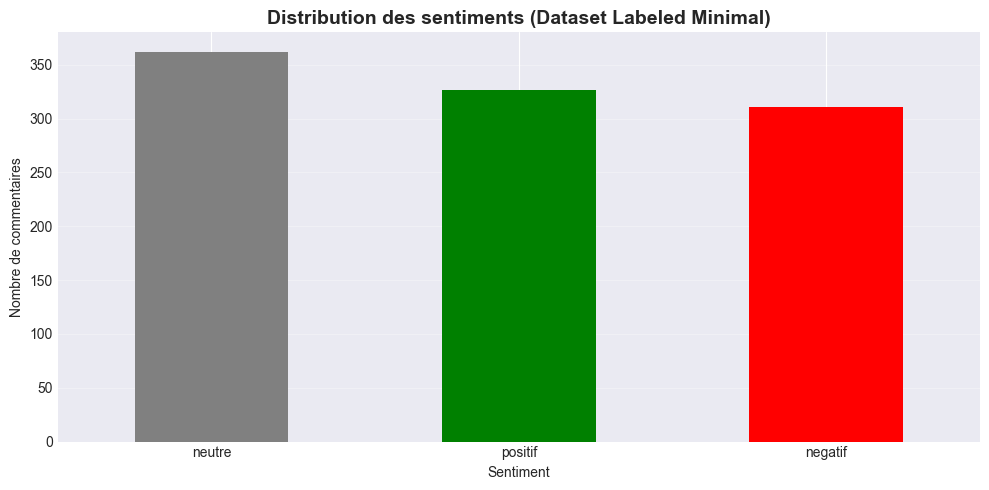

In [21]:
print("\n" + "="*70)
print("ÉTAPE 5: DISTRIBUTION DES SENTIMENTS")
print("="*70)

if 'sentiment' in df.columns:

    # CLEANING IMPORTANT
    df['sentiment'] = df['sentiment'].astype(str).str.strip().str.lower()

    sentiment_counts = df['sentiment'].value_counts()
    sentiment_pct = df['sentiment'].value_counts(normalize=True) * 100

    summary = pd.DataFrame({
        'Sentiment': sentiment_counts.index,
        'Nombre': sentiment_counts.values,
        'Pourcentage': sentiment_pct.values.round(2)
    })

    print("\nRépartition des sentiments:")
    display(summary)

    # Graphique
    fig, ax = plt.subplots(figsize=(10, 5))
    colors = {
    'positif': 'green',
    'negatif': 'red',
    'neutre': 'gray'
}

    sentiment_counts.plot(
        kind='bar',
        color=[colors.get(x, 'blue') for x in sentiment_counts.index]
)

    plt.title('Distribution des sentiments (Dataset Labeled Minimal)', fontsize=14, fontweight='bold')
    plt.ylabel('Nombre de commentaires')
    plt.xlabel('Sentiment')
    plt.xticks(rotation=0)
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("⚠️ Colonne 'sentiment' non trouvée")


 ÉTAPE 6: ANALYSE DE LA LONGUEUR DES TEXTES

Colonne utilisée pour l'analyse : text_clean

 Statistiques descriptives :


,char_length,word_count
count,1000.00,1000.00
mean,47.38,8.93
std,44.90,8.37
min,3.00,1.00
25%,19.00,4.00
50%,32.00,6.00
75%,57.25,11.00
max,290.00,49.00


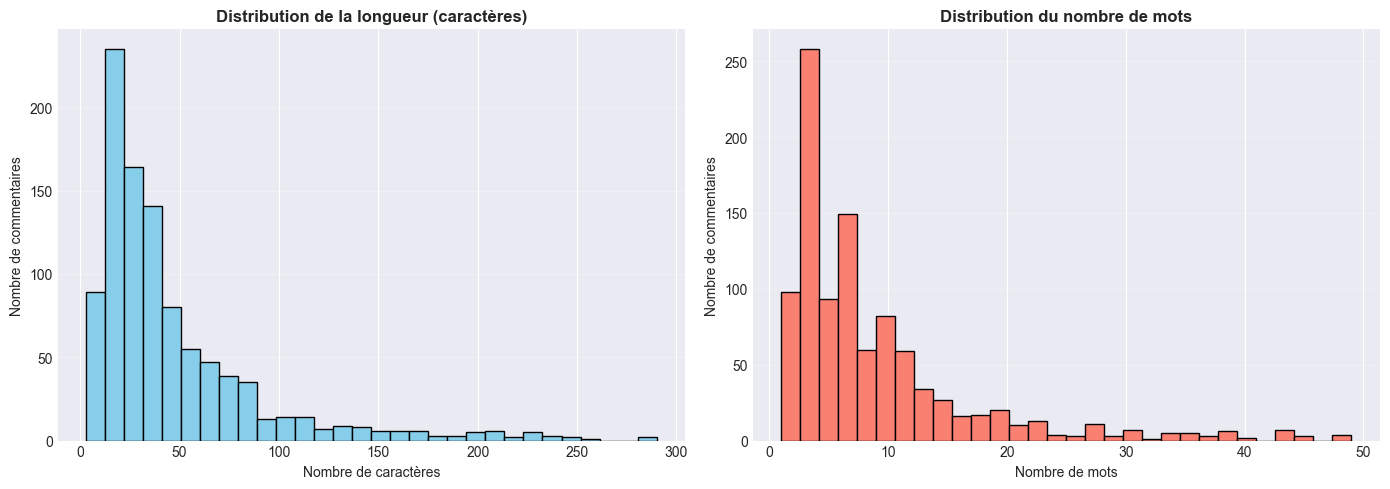

In [22]:
print("\n" + "="*70)
print(" ÉTAPE 6: ANALYSE DE LA LONGUEUR DES TEXTES")
print("="*70)

#  Détection automatique de la colonne texte
text_col = next((col for col in ['text_clean', 'text', 'comment', 'commentaire'] if col in df.columns), None)

if text_col:

    print(f"\nColonne utilisée pour l'analyse : {text_col}")

    # 📏 Calcul des longueurs
    df['char_length'] = df[text_col].astype(str).str.len()
    df['word_count'] = df[text_col].astype(str).str.split().str.len()

    # 📈 Statistiques globales
    stats = df[['char_length', 'word_count']].describe().round(2)

    print("\n Statistiques descriptives :")
    display(stats)

    

    # 📊 Visualisation
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Longueur en caractères
    axes[0].hist(df['char_length'], bins=30, color='skyblue', edgecolor='black')
    axes[0].set_title('Distribution de la longueur (caractères)', fontweight='bold')
    axes[0].set_xlabel('Nombre de caractères')
    axes[0].set_ylabel('Nombre de commentaires')
    axes[0].grid(axis='y', alpha=0.3)

    # Nombre de mots
    axes[1].hist(df['word_count'], bins=30, color='salmon', edgecolor='black')
    axes[1].set_title('Distribution du nombre de mots', fontweight='bold')
    axes[1].set_xlabel('Nombre de mots')
    axes[1].set_ylabel('Nombre de commentaires')
    axes[1].grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

else:
    print("⚠️ Aucune colonne texte trouvée dans le dataset")

Analyse des emoji

has_emoji
False    1000
Name: count, dtype: int64


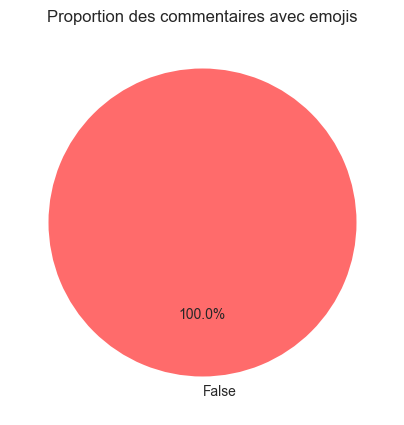

In [31]:
import re

emoji_pattern = re.compile(
    "[\U0001F600-\U0001F64F"  # emoticons
    "\U0001F300-\U0001F5FF"  # symbols & pictographs
    "\U0001F680-\U0001F6FF"  # transport & map
    "\U0001F1E0-\U0001F1FF"  # flags
    "\U00002700-\U000027BF"
    "]+",
    flags=re.UNICODE
)

df["has_emoji"] = df["text_clean"].astype(str).apply(lambda x: bool(emoji_pattern.search(x)))

print(df["has_emoji"].value_counts())

plt.figure(figsize=(5,5))
emoji_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    colors=["#ff6b6b", "#4ecdc4"],
    startangle=90
)

plt.title("Proportion des commentaires avec emojis")
plt.ylabel("")
plt.show()

L’analyse montre l’absence (ou la quasi-absence) d’emojis dans le dataset, ce qui indique que les étapes de nettoyage ont correctement supprimé les emojis lors du prétraitement des données.

Répartition des langues


 Répartition des langues :


language
darija (arabe)           552
latin (fr/en/arabizi)    419
mix (arabizi + arabe)     29
Name: count, dtype: int64

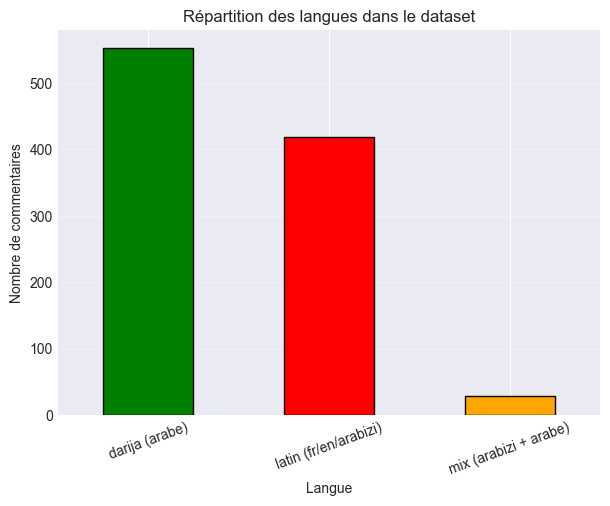


📌 Analyse qualitative des langues :

LANGUE : latin (fr/en/arabizi)
 Description : Texte écrit en alphabet latin .
Exemple 1 : hit ma3adnach baba 70 mmalyoun ahbibi la3ziz odarti had laviduo ghir 3la 9bal comontirat bach igolo lik hbibi la3ziiz otchharha
Exemple 2 : koun gha kant salma feida blast molat l rouge


LANGUE : darija (arabe)
 Description : Texte écrit uniquement en arabe dialectal marocain.
Exemple 1 : هنه 2026
Exemple 2 : الحزقه و الهوكي


LANGUE : mix (arabizi + arabe)
 Description : Mélange d'arabe et de latin dans le même commentaire.
Exemple 1 : فاش بدا كيعزف الݣيتار سحاب لي ai
Exemple 2 : الخراز we love your stories




In [27]:
import matplotlib.pyplot as plt
import re

# 🔍 Détection de langue améliorée
def detect_language(text):
    text = str(text)

    has_arabic = bool(re.search(r'[\u0600-\u06FF]', text))
    has_latin = bool(re.search(r'[a-zA-Z]', text))

    if has_arabic and has_latin:
        return "mix (arabizi + arabe)"
    elif has_arabic:
        return "darija (arabe)"
    elif has_latin:
        return "latin (fr/en/arabizi)"
    else:
        return "autre"

# 📌 Application
df["language"] = df["text_clean"].apply(detect_language)

#  Comptage
lang_counts = df["language"].value_counts()

print("\n Répartition des langues :")
display(lang_counts)

# 📈 Graphe
plt.figure(figsize=(7,5))
colors = ["green", "red", "orange", "purple"]

lang_counts.plot(
    kind="bar",
    color=colors[:len(lang_counts)],
    edgecolor="black"
)
plt.title("Répartition des langues dans le dataset")
plt.xlabel("Langue")
plt.ylabel("Nombre de commentaires")
plt.xticks(rotation=20)
plt.grid(axis='y', alpha=0.3)
plt.show()

# =========================================================
# 📌 EXPLICATION + EXEMPLES PAR LANGUE
# =========================================================

print("\n📌 Analyse qualitative des langues :\n")

language_description = {
    "darija (arabe)": "Texte écrit uniquement en arabe dialectal marocain.",
    "latin (fr/en/arabizi)": "Texte écrit en alphabet latin .",
    "mix (arabizi + arabe)": "Mélange d'arabe et de latin dans le même commentaire.",
    "autre": "Texte non standard ou vide."
}

for lang in df["language"].unique():

    print("=" * 70)
    print(f"LANGUE : {lang}")
    print(f" Description : {language_description.get(lang, 'Non défini')}")
    print("=" * 70)

    samples = df[df["language"] == lang]["text_clean"].dropna()

    if len(samples) > 0:
        samples = samples.sample(min(2, len(samples)), random_state=42)

        for i, ex in enumerate(samples, 1):
            print(f"Exemple {i} : {ex}")

    print("\n")